**import libraries**

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import os
import warnings
from pathlib import Path
import re

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

**Configure Project Paths**

In [3]:
PROJECT_ROOT = Path.cwd().parent

DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw" / "CICIDS2017"
DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

DATA_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project Root:", PROJECT_ROOT)
print("Raw Dataset:", DATA_RAW_DIR)
print("Processed Data:", DATA_PROCESSED_DIR)
print("Results:", RESULTS_FIGURES_DIR)

Project Root: D:\AI-IDS
Raw Dataset: D:\AI-IDS\data\raw\CICIDS2017
Processed Data: D:\AI-IDS\data\processed
Results: D:\AI-IDS\results\figures


**Find Dataset Files**

In [4]:
csv_files = sorted(DATA_RAW_DIR.glob("*.csv"))

print(f"Number of CSV files found: {len(csv_files)}")

if not csv_files:
    raise FileNotFoundError(
        f"No CICIDS2017 CSV files found in: {DATA_RAW_DIR}"
    )

Number of CSV files found: 8


**Load the CICIDS2017 Dataset**

In [5]:
dataframes = []

for file in csv_files:
    print(f"Loading: {file.name}")

    temp_df = pd.read_csv(
        file,
        low_memory=False
    )

    temp_df.columns = temp_df.columns.str.strip()

    dataframes.append(temp_df)

df = pd.concat(
    dataframes,
    ignore_index=True
)

print("\nDataset loaded successfully.")
print("Dataset Shape:", df.shape)

Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv

Dataset loaded successfully.
Dataset Shape: (2830743, 79)


**Dataset Inspection**

In [6]:
print(df.shape)

display(df.head())

print("Missing values:")
missing_val= df.isnull().sum()

missing_val = missing_val[missing_val > 0].sort_values(ascending=False)

if len(missing_val) == 0:
    print("No missing values found.")
else:
    display(missing_val)

(2830743, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,1.100917e+05,18348.62385,109.0,0.0,109,109,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,9174.311927,9174.311927,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,2.307692e+05,38461.53846,52.0,0.0,52,52,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,19230.769230,19230.769230,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,3.529412e+05,58823.52941,34.0,0.0,34,34,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,29411.764710,29411.764710,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


Missing values:


Flow Bytes/s    1358
dtype: int64

In [7]:
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 308381


**Standardize Column Names**

In [8]:
def clean_column_name(column):
    column = str(column).strip()
    column = column.replace(" ", "_")
    column = re.sub(r"[^A-Za-z0-9_]", "", column)
    column = re.sub(r"_+", "_", column)
    return column


df.columns = [clean_column_name(col) for col in df.columns]

print("Cleaned column names:")
print(df.columns.tolist())

Cleaned column names:
['Destination_Port', 'Flow_Duration', 'Total_Fwd_Packets', 'Total_Backward_Packets', 'Total_Length_of_Fwd_Packets', 'Total_Length_of_Bwd_Packets', 'Fwd_Packet_Length_Max', 'Fwd_Packet_Length_Min', 'Fwd_Packet_Length_Mean', 'Fwd_Packet_Length_Std', 'Bwd_Packet_Length_Max', 'Bwd_Packet_Length_Min', 'Bwd_Packet_Length_Mean', 'Bwd_Packet_Length_Std', 'Flow_Bytess', 'Flow_Packetss', 'Flow_IAT_Mean', 'Flow_IAT_Std', 'Flow_IAT_Max', 'Flow_IAT_Min', 'Fwd_IAT_Total', 'Fwd_IAT_Mean', 'Fwd_IAT_Std', 'Fwd_IAT_Max', 'Fwd_IAT_Min', 'Bwd_IAT_Total', 'Bwd_IAT_Mean', 'Bwd_IAT_Std', 'Bwd_IAT_Max', 'Bwd_IAT_Min', 'Fwd_PSH_Flags', 'Bwd_PSH_Flags', 'Fwd_URG_Flags', 'Bwd_URG_Flags', 'Fwd_Header_Length', 'Bwd_Header_Length', 'Fwd_Packetss', 'Bwd_Packetss', 'Min_Packet_Length', 'Max_Packet_Length', 'Packet_Length_Mean', 'Packet_Length_Std', 'Packet_Length_Variance', 'FIN_Flag_Count', 'SYN_Flag_Count', 'RST_Flag_Count', 'PSH_Flag_Count', 'ACK_Flag_Count', 'URG_Flag_Count', 'CWE_Flag_Count

**Clean the Target Labels**

In [9]:
df["Label"] = (
    df["Label"]
    .astype(str)
    .str.strip()
)

print("Unique labels:")
print(df["Label"].unique())

Unique labels:
<StringArray>
[                    'BENIGN',                       'DDoS',                   'PortScan',
                        'Bot',               'Infiltration',   'Web Attack � Brute Force',
           'Web Attack � XSS', 'Web Attack � Sql Injection',                'FTP-Patator',
                'SSH-Patator',              'DoS slowloris',           'DoS Slowhttptest',
                   'DoS Hulk',              'DoS GoldenEye',                 'Heartbleed']
Length: 15, dtype: str


In [10]:
print("Label distribution:")

label_counts = df["Label"].value_counts()

display(label_counts.to_frame("Count"))

Label distribution:


,Count
Label,
BENIGN,2273097
DoS Hulk,231073
PortScan,158930
DDoS,128027
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499


**Visualize Class Distribution**

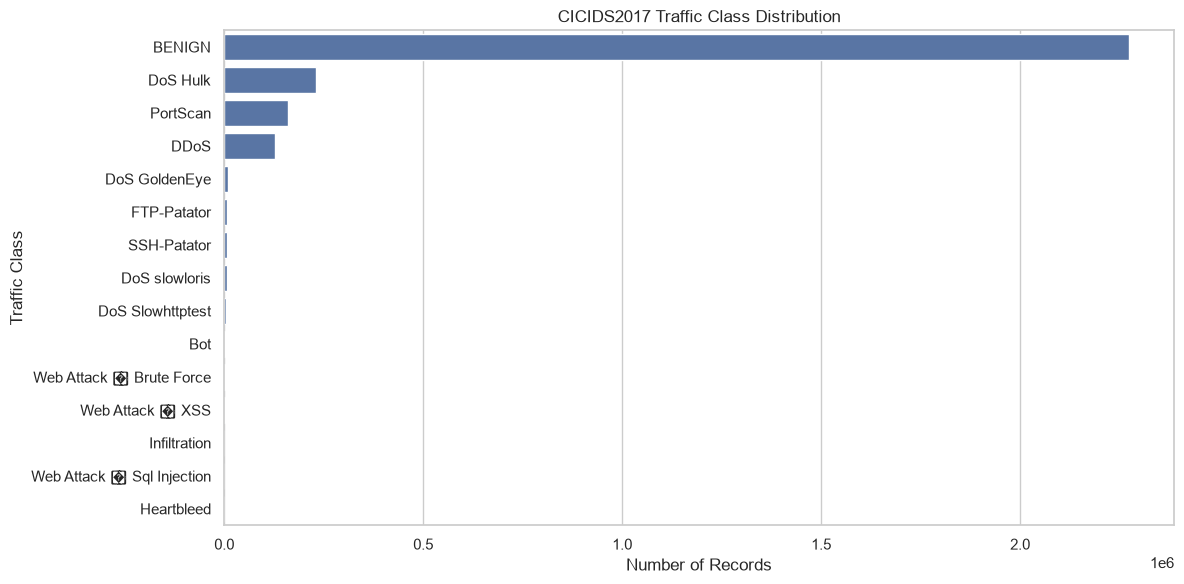

Figure saved to: D:\AI-IDS\results\figures\class_distribution.png


In [11]:
plt.figure(figsize=(12, 6))

ax = sns.countplot(
    data=df,
    y="Label",
    order=df["Label"].value_counts().index
)

plt.title("CICIDS2017 Traffic Class Distribution")
plt.xlabel("Number of Records")
plt.ylabel("Traffic Class")

plt.tight_layout()

figure_path = RESULTS_FIGURES_DIR / "class_distribution.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Figure saved to:", figure_path)

**Remove Invalid Numeric Values**

In [12]:
# Convert numeric-looking columns to numeric where possible
for column in df.columns:
    if column != "Label":
        df[column] = pd.to_numeric(df[column], errors="coerce")

# Replace positive and negative infinity
df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Infinite values remaining:", np.isinf(df.select_dtypes(include=np.number)).sum().sum())
print("Missing values after numeric conversion:", df.isnull().sum().sum())

Infinite values remaining: 0
Missing values after numeric conversion: 5734


**Handle Missing Values**

In [13]:
df.dropna(inplace=True)

**Remove Duplicate Network Flows**

In [14]:
df.drop_duplicates(inplace=True)

**Final Cleaned Dataset**

In [15]:
print("Final cleaned dataset shape:")
print(df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nInfinite numeric values:")
numeric_df = df.select_dtypes(include=np.number)
print(np.isinf(numeric_df).sum().sum())

print("\nData types:")
display(df.dtypes.value_counts())

print("\nLabel distribution:")
display(df["Label"].value_counts())

Final cleaned dataset shape:
(2520798, 79)

Missing values:
0

Duplicate rows:
0

Infinite numeric values:
0

Data types:


int64      54
float64    24
str         1
Name: count, dtype: int64


Label distribution:


Label
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

**Exploratory Data Analysis**

In [16]:
df.describe()

,Destination_Port,Flow_Duration,Total_Fwd_Packets,Total_Backward_Packets,Total_Length_of_Fwd_Packets,Total_Length_of_Bwd_Packets,Fwd_Packet_Length_Max,Fwd_Packet_Length_Min,Fwd_Packet_Length_Mean,Fwd_Packet_Length_Std,Bwd_Packet_Length_Max,Bwd_Packet_Length_Min,Bwd_Packet_Length_Mean,Bwd_Packet_Length_Std,Flow_Bytess,Flow_Packetss,Flow_IAT_Mean,Flow_IAT_Std,Flow_IAT_Max,Flow_IAT_Min,Fwd_IAT_Total,Fwd_IAT_Mean,Fwd_IAT_Std,Fwd_IAT_Max,Fwd_IAT_Min,Bwd_IAT_Total,Bwd_IAT_Mean,Bwd_IAT_Std,Bwd_IAT_Max,Bwd_IAT_Min,Fwd_PSH_Flags,Bwd_PSH_Flags,Fwd_URG_Flags,Bwd_URG_Flags,Fwd_Header_Length,Bwd_Header_Length,Fwd_Packetss,Bwd_Packetss,Min_Packet_Length,Max_Packet_Length,Packet_Length_Mean,Packet_Length_Std,Packet_Length_Variance,FIN_Flag_Count,SYN_Flag_Count,RST_Flag_Count,PSH_Flag_Count,ACK_Flag_Count,URG_Flag_Count,CWE_Flag_Count,ECE_Flag_Count,DownUp_Ratio,Average_Packet_Size,Avg_Fwd_Segment_Size,Avg_Bwd_Segment_Size,Fwd_Header_Length1,Fwd_Avg_BytesBulk,Fwd_Avg_PacketsBulk,Fwd_Avg_Bulk_Rate,Bwd_Avg_BytesBulk,Bwd_Avg_PacketsBulk,Bwd_Avg_Bulk_Rate,Subflow_Fwd_Packets,Subflow_Fwd_Bytes,Subflow_Bwd_Packets,Subflow_Bwd_Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active_Mean,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min
count,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2520798.0,2.520798e+06,2520798.0,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2520798.0,2520798.0,2520798.0,2520798.0,2520798.0,2520798.0,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06,2.520798e+06
mean,8.690590e+03,1.659161e+07,1.028174e+01,1.157280e+01,6.119477e+02,1.814440e+04,2.312292e+02,1.920349e+01,6.350497e+01,7.732347e+01,9.749726e+02,4.315945e+01,3.406225e+02,3.765453e+02,1.410707e+06,4.729188e+04,1.446142e+06,3.278153e+06,1.029948e+07,1.704214e+05,1.625184e+07,2.919257e+06,3.668641e+06,1.014294e+07,1.135671e+06,1.111025e+07,2.027734e+06,1.668681e+06,5.260619e+06,1.086111e+06,4.866832e-02,0.0,3.173598e-05,0.0,-2.920023e+04,-2.555236e+03,4.085969e+04,6.513513e+03,1.683200e+01,1.063750e+03,1.906548e+02,3.302006e+02,5.457761e+05,3.209539e-02,4.866832e-02,2.721360e-04,2.976085e-01,3.118723e-01,1.013929e-01,3.173598e-05,2.733261e-04,7.004476e-01,2.124358e+02,6.350497e+01,3.406225e+02,-2.920023e+04,0.0,0.0,0.0,0.0,0.0,0.0,1.028174e+01,6.119359e+02,1.157280e+01,1.814402e+04,7.265614e+03,2.228725e+03,6.009478e+00,-3.082233e+03,9.157847e+04,4.619177e+04,1.720171e+05,6.546359e+04,9.337367e+06,5.657941e+05,9.763770e+06,8.892671e+06
std,1.901280e+04,3.523276e+07,7.944201e+02,1.056922e+03,1.058827e+04,2.398177e+06,7.563755e+02,6.079834e+01,1.955526e+02,2.968814e+02,2.038347e+03,7.087972e+01,6.325636e+02,8.810547e+02,2.657084e+07,2.026366e+05,4.683197e+06,8.456754e+06,2.568537e+07,3.014304e+06,3.516638e+07,1.001639e+07,1.014208e+07,2.576650e+07,9.059498e+06,3.022924e+07,9.393386e+06,6.630315e+06,1.810168e+07,8.797215e+06,2.151737e-01,0.0,5.633382e-03,0.0,2.230962e+07,1.538899e+06,1.932655e+05,3.814460e+04,2.558415e+01,2.121693e+03,3.183562e+02,6.608889e+02,1.736478e+06,1.762535e-01,2.151737e-01,1.649430e-02,4.572065e-01,4.632581e-01,3.018483e-01,5.633382e-03,1.653032e-02,6.956600e-01,3.455032e+02,1.955526e+02,6.325636e+02,2.230962e+07,0.0,0.0,0.0,0.0,0.0,0.0,7.944201e+02,1.05739

**Exploratory Data Analysis (EDA)**

In [17]:
# 1.Feature Distribution Analysis

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

# Select up to 12 numerical features for visualization
selected_features = numeric_columns[:12]

print("Features selected for distribution analysis:")
print(selected_features)

Features selected for distribution analysis:
['Destination_Port', 'Flow_Duration', 'Total_Fwd_Packets', 'Total_Backward_Packets', 'Total_Length_of_Fwd_Packets', 'Total_Length_of_Bwd_Packets', 'Fwd_Packet_Length_Max', 'Fwd_Packet_Length_Min', 'Fwd_Packet_Length_Mean', 'Fwd_Packet_Length_Std', 'Bwd_Packet_Length_Max', 'Bwd_Packet_Length_Min']


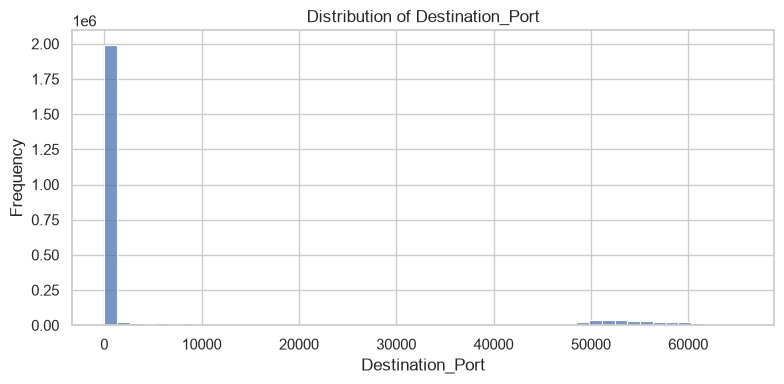

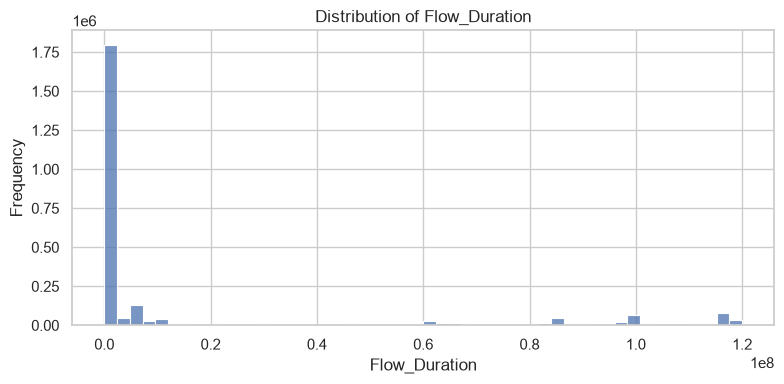

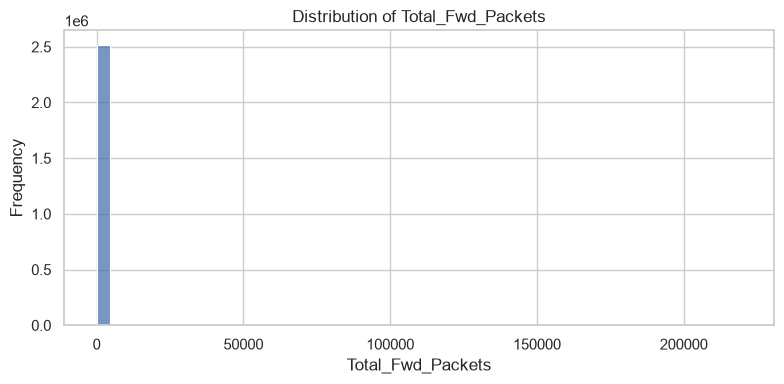

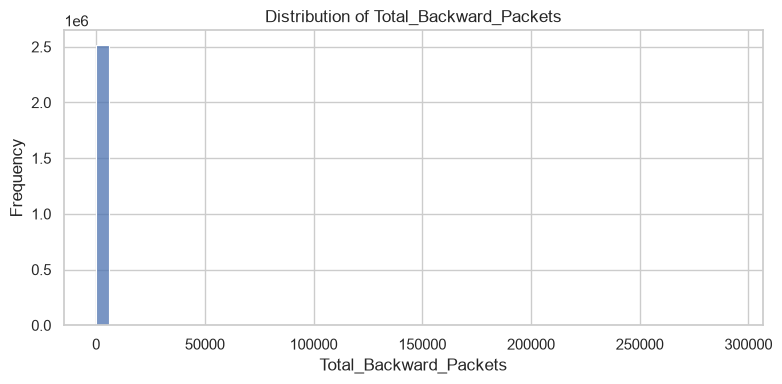

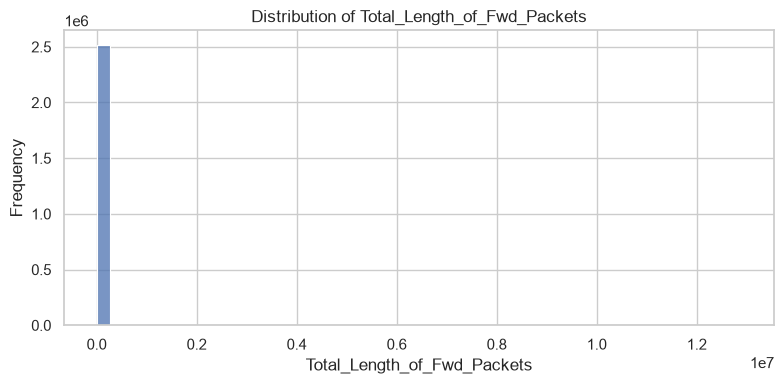

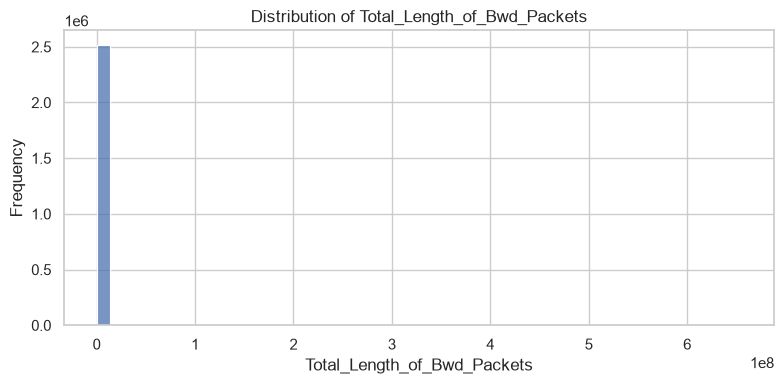

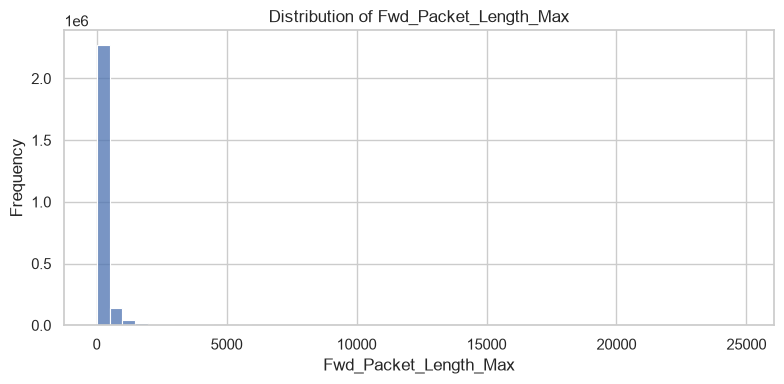

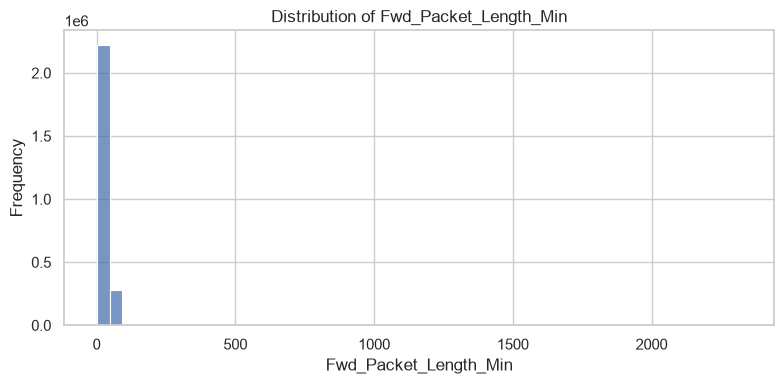

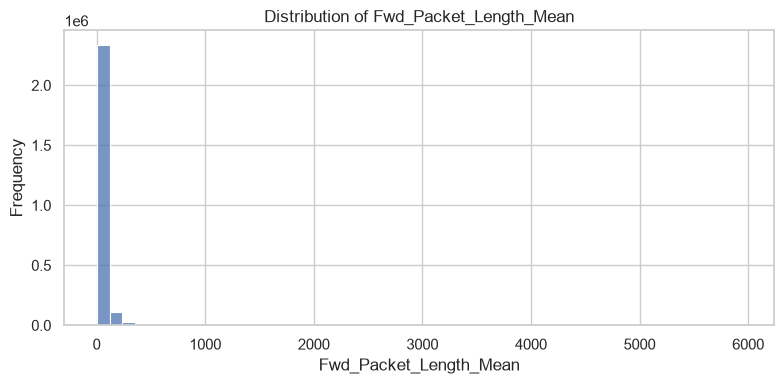

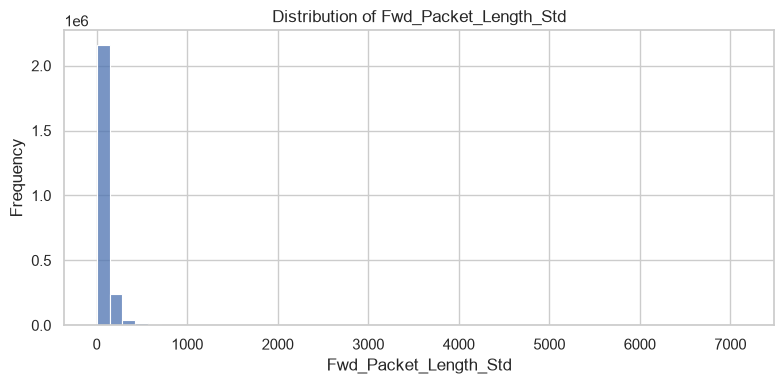

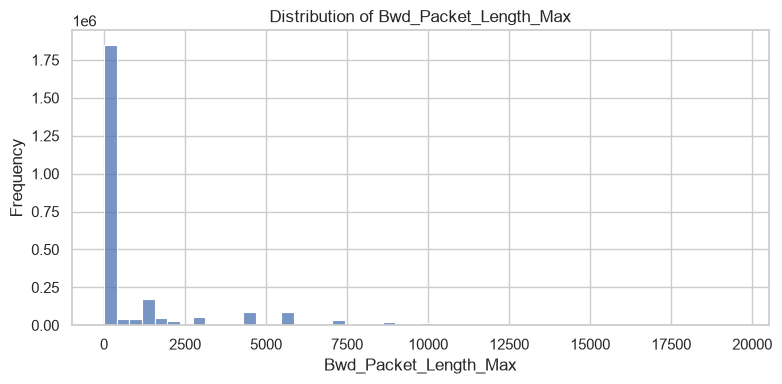

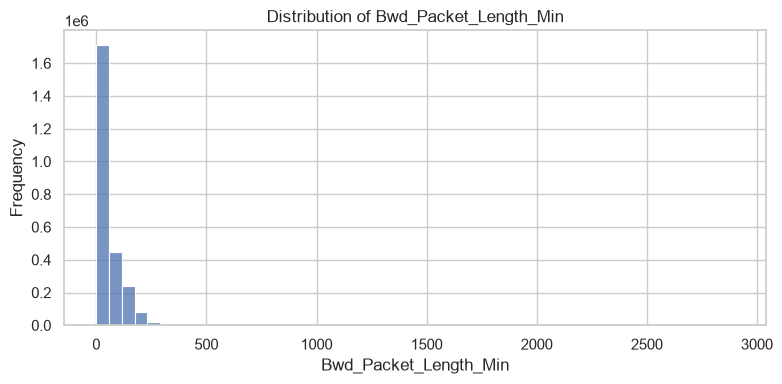

In [18]:
for feature in selected_features:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        df[feature],
        bins=50,
        kde=False
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.tight_layout()

    safe_name = feature.replace("/", "_")
    figure_path = RESULTS_FIGURES_DIR / f"distribution_{safe_name}.png"

    plt.savefig(figure_path, dpi=200, bbox_inches="tight")
    plt.show()

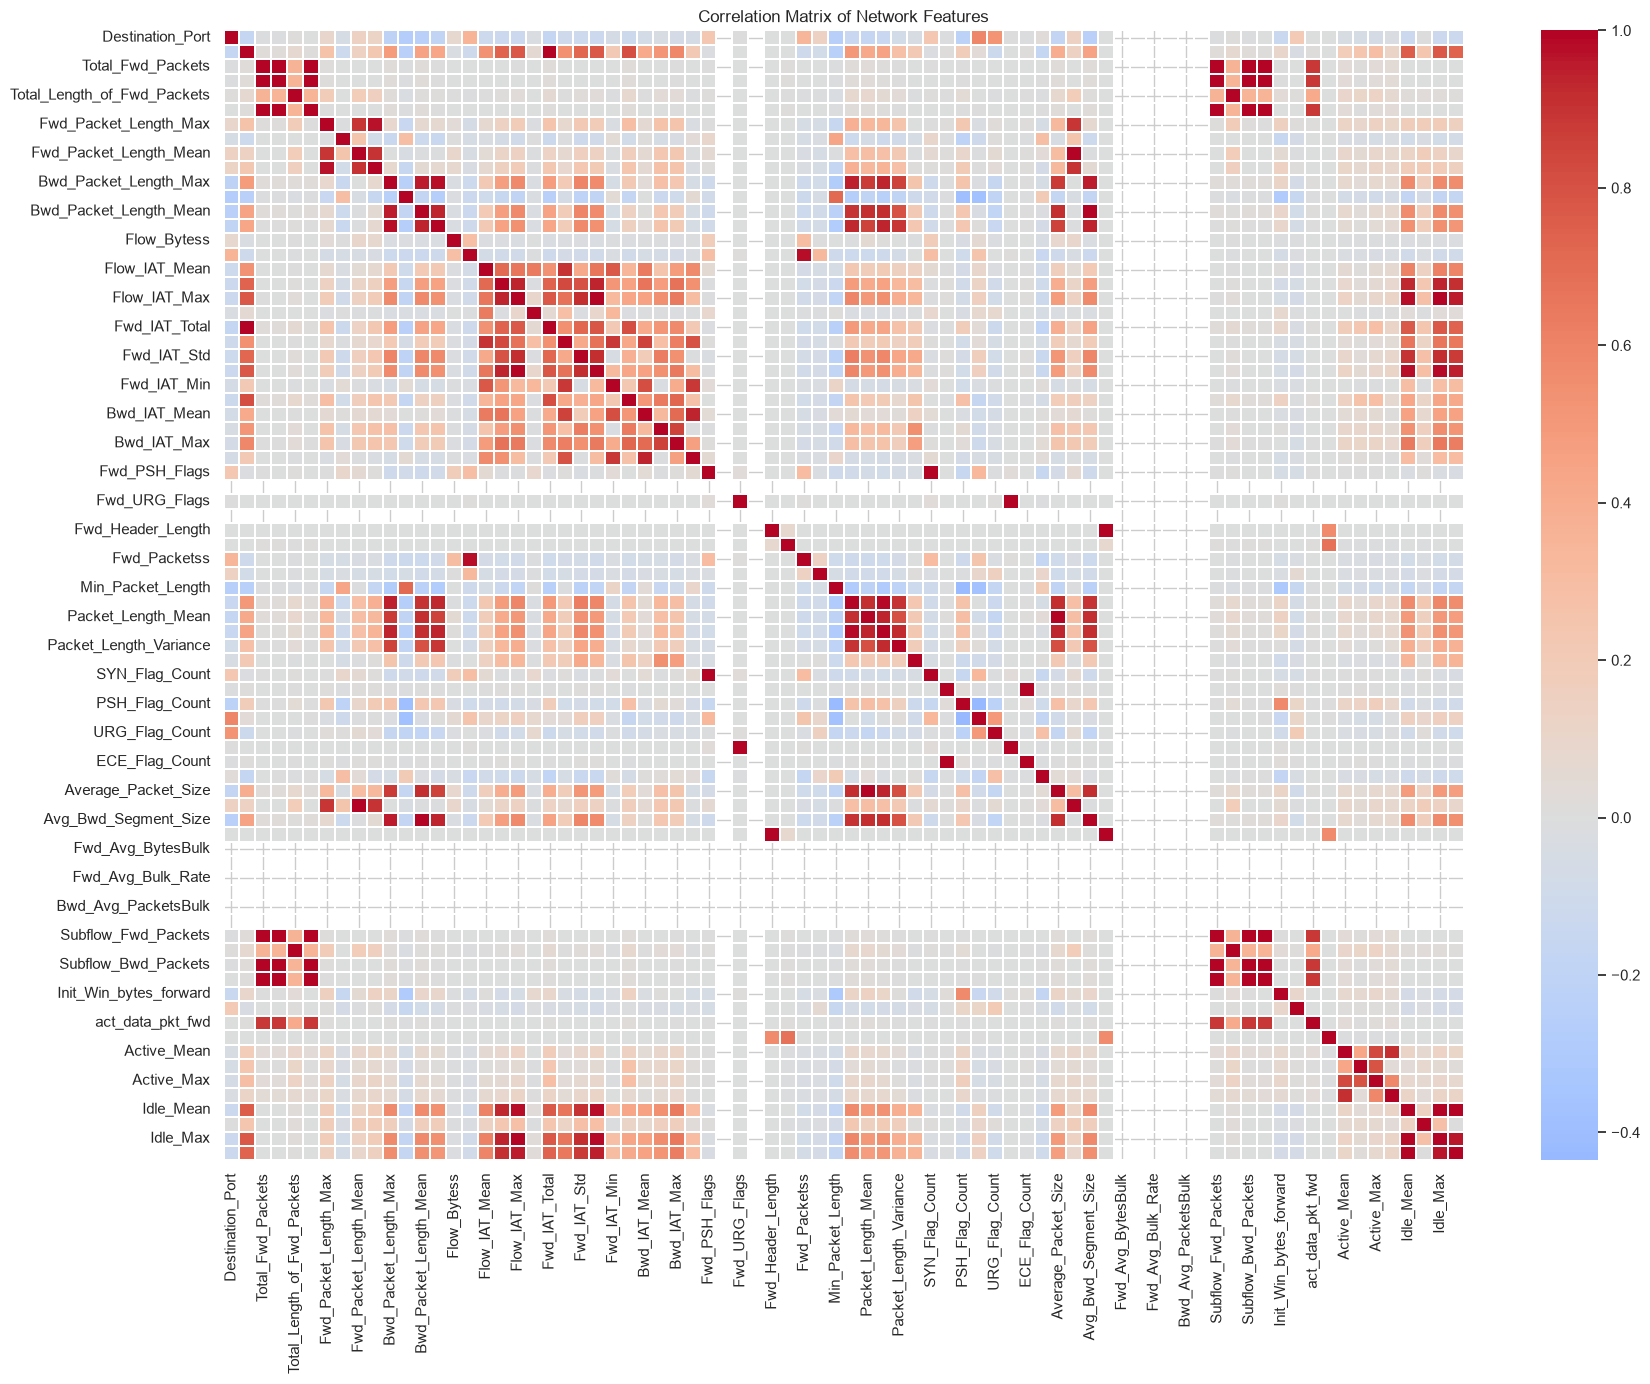

Correlation heatmap saved to: D:\AI-IDS\results\figures\correlation_heatmap.png


In [19]:
# 2.Correlation Analysis

# Limit correlation analysis to numerical columns
correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Matrix of Network Features")

plt.tight_layout()

figure_path = RESULTS_FIGURES_DIR / "correlation_heatmap.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Correlation heatmap saved to:", figure_path)

**Feature Engineering**

In [20]:
def safe_divide(numerator, denominator):
    """
    Safely divide two pandas Series.
    Zero denominators result in 0 instead of infinity.
    """
    denominator = denominator.replace(0, np.nan)
    result = numerator / denominator

    return result.replace([np.inf, -np.inf], np.nan).fillna(0)


# Create additional features only if the required source columns exist

if {"Total_Fwd_Packets", "Total_Backward_Packets"}.issubset(df.columns):
    df["Fwd_Bwd_Packet_Ratio"] = safe_divide(
        df["Total_Fwd_Packets"],
        df["Total_Backward_Packets"]
    )

if {"Total_Length_of_Fwd_Packets", "Total_Length_of_Bwd_Packets"}.issubset(df.columns):
    df["Fwd_Bwd_Byte_Ratio"] = safe_divide(
        df["Total_Length_of_Fwd_Packets"],
        df["Total_Length_of_Bwd_Packets"]
    )

if {"Total_Length_of_Fwd_Packets", "Total_Fwd_Packets"}.issubset(df.columns):
    df["Avg_Fwd_Packet_Size"] = safe_divide(
        df["Total_Length_of_Fwd_Packets"],
        df["Total_Fwd_Packets"]
    )

if {"Total_Length_of_Bwd_Packets", "Total_Backward_Packets"}.issubset(df.columns):
    df["Avg_Bwd_Packet_Size"] = safe_divide(
        df["Total_Length_of_Bwd_Packets"],
        df["Total_Backward_Packets"]
    )

print("Feature engineering completed.")

Feature engineering completed.


In [21]:
engineered_features = [
    "Fwd_Bwd_Packet_Ratio",
    "Fwd_Bwd_Byte_Ratio",
    "Avg_Fwd_Packet_Size",
    "Avg_Bwd_Packet_Size"
]

available_engineered = [
    feature for feature in engineered_features
    if feature in df.columns
]

print("Engineered features:")
for feature in available_engineered:
    print(" -", feature)

Engineered features:
 - Fwd_Bwd_Packet_Ratio
 - Fwd_Bwd_Byte_Ratio
 - Avg_Fwd_Packet_Size
 - Avg_Bwd_Packet_Size


**Create Binary Intrusion Target**

In [22]:
df["Attack"] = (
    df["Label"]
    .str.upper()
    .ne("BENIGN")
    .astype(int)
)

print("Binary target distribution:")

binary_distribution = df["Attack"].value_counts().rename(
    index={
        0: "BENIGN",
        1: "ATTACK"
    }
)
display(binary_distribution.to_frame("Count"))

Binary target distribution:


,Count
Attack,
BENIGN,2095057
ATTACK,425741


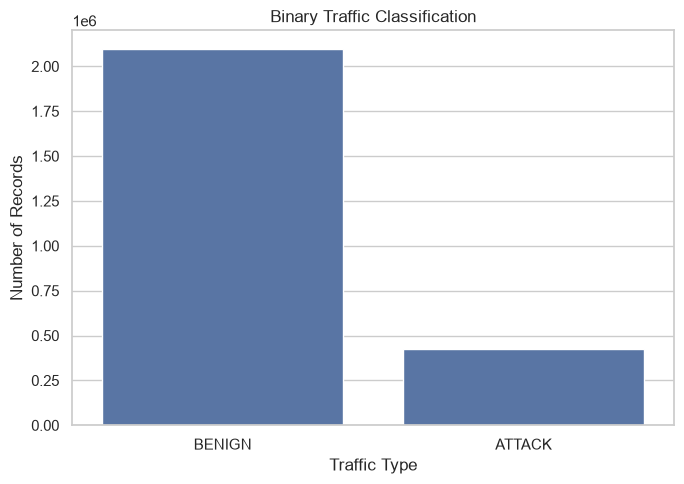

In [23]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x=df["Attack"].map({
        0: "BENIGN",
        1: "ATTACK"
    })
)

plt.title("Binary Traffic Classification")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.tight_layout()

figure_path = RESULTS_FIGURES_DIR / "binary_class_distribution.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

**Feature Selection**

In [24]:
# Columns that should not be used directly as ML features
columns_to_exclude = [
    "Label",
    "Attack",
    "Flow_ID",
    "Source_IP",
    "Destination_IP",
    "Timestamp"
]

feature_columns = [
    column
    for column in df.columns
    if column not in columns_to_exclude
]

# Keep only numerical features
feature_columns = [
    column
    for column in feature_columns
    if pd.api.types.is_numeric_dtype(df[column])
]

print(f"Number of selected features: {len(feature_columns)}")

print("\nSelected features:")
for feature in feature_columns:
    print(" -", feature)

Number of selected features: 82

Selected features:
 - Destination_Port
 - Flow_Duration
 - Total_Fwd_Packets
 - Total_Backward_Packets
 - Total_Length_of_Fwd_Packets
 - Total_Length_of_Bwd_Packets
 - Fwd_Packet_Length_Max
 - Fwd_Packet_Length_Min
 - Fwd_Packet_Length_Mean
 - Fwd_Packet_Length_Std
 - Bwd_Packet_Length_Max
 - Bwd_Packet_Length_Min
 - Bwd_Packet_Length_Mean
 - Bwd_Packet_Length_Std
 - Flow_Bytess
 - Flow_Packetss
 - Flow_IAT_Mean
 - Flow_IAT_Std
 - Flow_IAT_Max
 - Flow_IAT_Min
 - Fwd_IAT_Total
 - Fwd_IAT_Mean
 - Fwd_IAT_Std
 - Fwd_IAT_Max
 - Fwd_IAT_Min
 - Bwd_IAT_Total
 - Bwd_IAT_Mean
 - Bwd_IAT_Std
 - Bwd_IAT_Max
 - Bwd_IAT_Min
 - Fwd_PSH_Flags
 - Bwd_PSH_Flags
 - Fwd_URG_Flags
 - Bwd_URG_Flags
 - Fwd_Header_Length
 - Bwd_Header_Length
 - Fwd_Packetss
 - Bwd_Packetss
 - Min_Packet_Length
 - Max_Packet_Length
 - Packet_Length_Mean
 - Packet_Length_Std
 - Packet_Length_Variance
 - FIN_Flag_Count
 - SYN_Flag_Count
 - RST_Flag_Count
 - PSH_Flag_Count
 - ACK_Flag_Count
 - U

**Remove Constant Features**

In [28]:
constant_features = [
    column
    for column in feature_columns
    if df[column].nunique(dropna=False) <= 1
]

print("Constant features found:")
print(constant_features)

Constant features found:
[]


In [29]:
feature_columns = [
    column
    for column in feature_columns
    if column not in constant_features
]

print(f"\nFeatures remaining: {len(feature_columns)}")


Features remaining: 74


**Prepare Machine Learning Dataset**

In [30]:
X = df[feature_columns].copy()
y = df["Attack"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Feature matrix shape: (2520798, 74)
Target shape: (2520798,)


,Destination_Port,Flow_Duration,Total_Fwd_Packets,Total_Backward_Packets,Total_Length_of_Fwd_Packets,Total_Length_of_Bwd_Packets,Fwd_Packet_Length_Max,Fwd_Packet_Length_Min,Fwd_Packet_Length_Mean,Fwd_Packet_Length_Std,Bwd_Packet_Length_Max,Bwd_Packet_Length_Min,Bwd_Packet_Length_Mean,Bwd_Packet_Length_Std,Flow_Bytess,Flow_Packetss,Flow_IAT_Mean,Flow_IAT_Std,Flow_IAT_Max,Flow_IAT_Min,Fwd_IAT_Total,Fwd_IAT_Mean,Fwd_IAT_Std,Fwd_IAT_Max,Fwd_IAT_Min,Bwd_IAT_Total,Bwd_IAT_Mean,Bwd_IAT_Std,Bwd_IAT_Max,Bwd_IAT_Min,Fwd_PSH_Flags,Fwd_URG_Flags,Fwd_Header_Length,Bwd_Header_Length,Fwd_Packetss,Bwd_Packetss,Min_Packet_Length,Max_Packet_Length,Packet_Length_Mean,Packet_Length_Std,Packet_Length_Variance,FIN_Flag_Count,SYN_Flag_Count,RST_Flag_Count,PSH_Flag_Count,ACK_Flag_Count,URG_Flag_Count,CWE_Flag_Count,ECE_Flag_Count,DownUp_Ratio,Average_Packet_Size,Avg_Fwd_Segment_Size,Avg_Bwd_Segment_Size,Fwd_Header_Length1,Subflow_Fwd_Packets,Subflow_Fwd_Bytes,Subflow_Bwd_Packets,Subflow_Bwd_Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active_Mean,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min,Fwd_Bwd_Packet_Ratio,Fwd_Bwd_Byte_Ratio,Avg_Fwd_Packet_Size,Avg_Bwd_Packet_Size
0,54865,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,2,12,0,0,33,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,6.0,0.0
1,55054,109,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,1.100917e+05,18348.62385,109.0,0.0,109,109,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,20,20,9174.311927,9174.311927,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,1.0,1.0,6.0,6.0
2,55055,52,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,2.307692e+05,38461.53846,52.0,0.0,52,52,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,20,20,19230.769230,19230.769230,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,1.0,1.0,6.0,6.0
3,46236,34,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,3.529412e+05,58823.52941,34.0,0.0,34,34,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,20,20,29411.764710,29411.764710,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,1,6,1,6,31,329,0,20,0.0,0.0,0,0,0.0,0.0,0,0,1.0,1.0,6.0,6.0
4,54863,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,2,12,0,0,32,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,0.0,0.0,6.0,0.0


0    0
1    0
2    0
3    0
4    0
Name: Attack, dtype: int64

**Train,Validate & Test Split**

In [32]:
X_train, X_temp, y_train, y_temp = train_test_split(X,y,test_size=0.30,random_state=42,stratify=y)

# Result: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Dataset split completed.\n")
print(f"Training set:   {X_train.shape}")
print(f"Validation set: {X_val.shape}")
print(f"Test set:       {X_test.shape}")

Dataset split completed.

Training set:   (1764558, 74)
Validation set: (378120, 74)
Test set:       (378120, 74)


In [33]:
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Samples": [
        len(y_train),
        len(y_val),
        len(y_test)
    ],
    "Attack (%)": [
        y_train.mean() * 100,
        y_val.mean() * 100,
        y_test.mean() * 100
    ],
    "Benign (%)": [
        (1 - y_train.mean()) * 100,
        (1 - y_val.mean()) * 100,
        (1 - y_test.mean()) * 100
    ]
})

display(split_summary)

,Dataset,Samples,Attack (%),Benign (%)
0,Training,1764558,16.889159,83.110841
1,Validation,378120,16.889083,83.110917
2,Test,378120,16.889083,83.110917


**Save Processed Datasets**

In [35]:
train_data = X_train.copy()
train_data["Attack"] = y_train.values

validation_data = X_val.copy()
validation_data["Attack"] = y_val.values

test_data = X_test.copy()
test_data["Attack"] = y_test.values


train_path = DATA_PROCESSED_DIR / "train.csv"
validation_path = DATA_PROCESSED_DIR / "validation.csv"
test_path = DATA_PROCESSED_DIR / "test.csv"

train_data.to_csv(train_path, index=False)
validation_data.to_csv(validation_path, index=False)
test_data.to_csv(test_path, index=False)

print("Processed datasets saved successfully:")
print(train_path)
print(validation_path)
print(test_path)

Processed datasets saved successfully:
D:\AI-IDS\data\processed\train.csv
D:\AI-IDS\data\processed\validation.csv
D:\AI-IDS\data\processed\test.csv


**Save Feature Configuration**

In [36]:
import json

feature_config = {
    "target": "Attack",
    "target_mapping": {
        "BENIGN": 0,
        "ATTACK": 1
    },
    "features": feature_columns,
    "number_of_features": len(feature_columns)
}

feature_config_path = DATA_PROCESSED_DIR / "feature_config.json"

with open(feature_config_path, "w") as file:
    json.dump(feature_config, file, indent=4)

print("Feature configuration saved to:")
print(feature_config_path)

Feature configuration saved to:
D:\AI-IDS\data\processed\feature_config.json
